# 1. Análisis Exploratorio de Datos (EDA) - Sistema Solar Popayán

Comenzaremos cargando el conjunto de datos, visualizando sus primeras filas, comprendiendo la estructura de sus columnas y analizando las relaciones estadísticas entre las variables meteorológicas y la generación de energía solar.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo para los gráficos
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Cargar el dataset
filepath = '/content/dataset_sistema_solar_popayan_2023_2026_v6.csv'
df = pd.read_csv(filepath)

# Información estructural del dataset
print("--- Estructura del dataset ---")
df.info()

print("\n--- Primeras 5 filas ---")
display(df.head())

--- Estructura del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29256 entries, 0 to 29255
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Timestamp           29256 non-null  object 
 1   P_DC_PV_W           29256 non-null  float64
 2   V_Batt_V            29256 non-null  float64
 3   I_Batt_A            29256 non-null  float64
 4   SoC_Batt_Pct        29256 non-null  float64
 5   V_AC_L1_V           29256 non-null  float64
 6   V_AC_L2_V           29256 non-null  float64
 7   V_AC_L3_V           29256 non-null  float64
 8   I_AC_L1_A           29256 non-null  float64
 9   I_AC_L2_A           29256 non-null  float64
 10  I_AC_L3_A           29256 non-null  float64
 11  Grid_Status         29256 non-null  object 
 12  Temp_Inverter_C     29256 non-null  float64
 13  Status_Code         29256 non-null  int64  
 14  Alarm_Event         29256 non-null  object 
 15  Fault_Duration_Min  29

,Timestamp,P_DC_PV_W,V_Batt_V,I_Batt_A,SoC_Batt_Pct,V_AC_L1_V,V_AC_L2_V,V_AC_L3_V,I_AC_L1_A,I_AC_L2_A,I_AC_L3_A,Grid_Status,Temp_Inverter_C,Status_Code,Alarm_Event,Fault_Duration_Min
0,2023-07-01 00:00:00,0.0,49.99,-32.0,66.6,119.4,119.1,119.0,12.28,11.94,12.07,On-Grid (Red/Descarga Noche),25.1,100,NONE,0
1,2023-07-01 01:00:00,0.0,49.33,-22.6,61.1,121.1,120.1,119.2,11.94,12.17,12.22,On-Grid (Red/Descarga Noche),25.1,100,NONE,0
2,2023-07-01 02:00:00,0.0,48.70,-13.9,55.8,118.8,118.4,121.2,11.52,11.60,11.72,On-Grid (Red/Descarga Noche),25.1,100,NONE,0
3,2023-07-01 03:00:00,0.0,47.94,-26.8,49.5,121.3,121.7,121.8,12.30,12.11,12.26,On-Grid (Red/Descarga Noche),25.1,100,NONE,0
4,2023-07-01 04:00:00,0.0,47.28,-25.4,44.0,119.8,119.8,118.2,11.97,12.11,11.99,On-Grid (Red/Descarga Noche),25.1,100,NONE,0


## Descripción de las Columnas del Dataset

A continuación describiremos las variables presentes en el dataset y su importancia para la predicción de generación solar:

In [ ]:
# Resumen estadístico de las variables
print("--- Resumen Estadístico Descriptivo ---")
display(df.describe())

--- Resumen Estadístico Descriptivo ---


,P_DC_PV_W,V_Batt_V,I_Batt_A,SoC_Batt_Pct,V_AC_L1_V,V_AC_L2_V,V_AC_L3_V,I_AC_L1_A,I_AC_L2_A,I_AC_L3_A,Temp_Inverter_C,Status_Code,Fault_Duration_Min
count,29256.00000,29256.000000,29256.000000,29256.000000,29256.000000,29256.000000,29256.000000,29256.000000,29256.000000,29256.000000,29256.000000,29256.000000,29256.000000
mean,2756.08911,50.502167,6.111622,70.859212,119.991715,120.001812,120.005052,12.271846,12.271729,12.272795,33.990375,100.328548,0.170221
std,3592.80194,2.207977,35.217287,18.387573,1.039025,1.043943,1.037697,0.506153,0.507058,0.507061,10.460359,11.466483,7.383464
min,0.00000,42.000000,-48.600000,0.000000,118.200000,118.200000,118.200000,0.000000,0.000000,0.000000,25.100000,100.000000,0.000000
25%,0.00000,49.100000,-24.300000,59.200000,119.100000,119.100000,119.100000,11.970000,11.970000,11.970000,25.100000,100.000000,0.000000
50%,0.00000,50.660000,-13.700000,72.200000,120.000000,120.000000,120.000000,12.280000,12.280000,12.280000,25.100000,100.000000,0.000000
75%,5919.47500,52.340000,40.300000,86.200000,120.900000,120.900000,120.900000,12.590000,12.590000,12.590000,44.300000,100.000000,0.000000
max,13058.60000,54.000000,89.400000,100.000000,121.800000,121.800000,121.800000,13.150000,13.150000,13.150000,58.700000,501.000000,360.000000


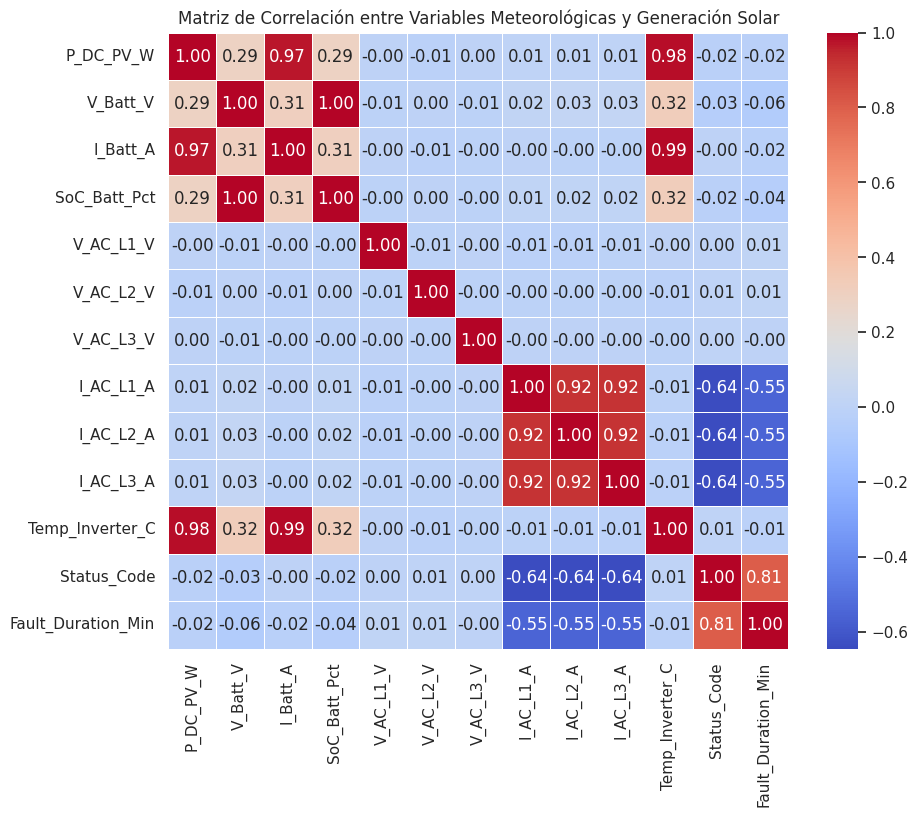

In [ ]:
# Conversión de fecha y visualización temporal
if 'Fecha' in df.columns:
    df['Fecha'] = pd.to_datetime(df['Fecha'])

# Identificar columnas clave para graficar distribuciones y correlaciones
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
target_col = [col for col in numeric_cols if 'generacion' in col.lower() or 'energia' in col.lower() or 'generation' in col.lower() or 'kwh' in col.lower()]
temp_col = [col for col in numeric_cols if 'temp' in col.lower()]
rad_col = [col for col in numeric_cols if 'irrad' in col.lower() or 'rad' in col.lower() or 'sol' in col.lower()]

# Matriz de Correlación
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación entre Variables Meteorológicas y Generación Solar')
plt.show()

In [ ]:
# Comportamiento histórico temporal de la generación
if len(target_col) > 0 and 'Fecha' in df.columns:
    plt.figure(figsize=(15, 6))
    # Agrupamos por mes para suavizar la serie y ver tendencias
    df_monthly = df.groupby(df['Fecha'].dt.to_period('M'))[target_col[0]].mean().reset_index()
    df_monthly['Fecha'] = df_monthly['Fecha'].dt.to_timestamp()

    sns.lineplot(data=df_monthly, x='Fecha', y=target_col[0], marker='o', color='orange', linewidth=2.5)
    plt.title('Tendencia Promedio Mensual de Generación Solar (Histórico)')
    plt.xlabel('Fecha')
    plt.ylabel(target_col[0])
    plt.grid(True)
    plt.show()

## Descripción Detallada de las Columnas

- **Timestamp**: Registro de fecha y hora de la medición (resolución horaria).
- **P_DC_PV_W**: Potencia de Corriente Continua (DC) generada por los paneles solares fotovoltaicos en Watts (W). Esta es nuestra **variable objetivo** para la generación solar.
- **V_Batt_V**: Voltaje de las baterías en Voltios (V).
- **I_Batt_A**: Corriente de las baterías en Amperios (A). Los valores negativos representan descarga (comúnmente de noche) y los positivos representan carga (durante el día).
- **SoC_Batt_Pct**: Estado de carga (State of Charge) de la batería expresado en porcentaje (0% a 100%).
- **V_AC_L1_V, V_AC_L2_V, V_AC_L3_V**: Voltajes de corriente alterna (AC) para las tres fases eléctricas de la red.
- **I_AC_L1_A, I_AC_L2_A, I_AC_L3_A**: Corrientes de corriente alterna (AC) para las tres fases eléctricas.
- **Grid_Status**: Estado de la red eléctrica comercial (ej. On-Grid, Off-Grid).
- **Temp_Inverter_C**: Temperatura interna del inversor solar en grados Celsius (°C).
- **Status_Code**: Código numérico que indica el estado operativo o modo del sistema.
- **Alarm_Event**: Registro de alarmas o eventos ocurridos en el sistema.
- **Fault_Duration_Min**: Duración de fallas registradas en minutos.

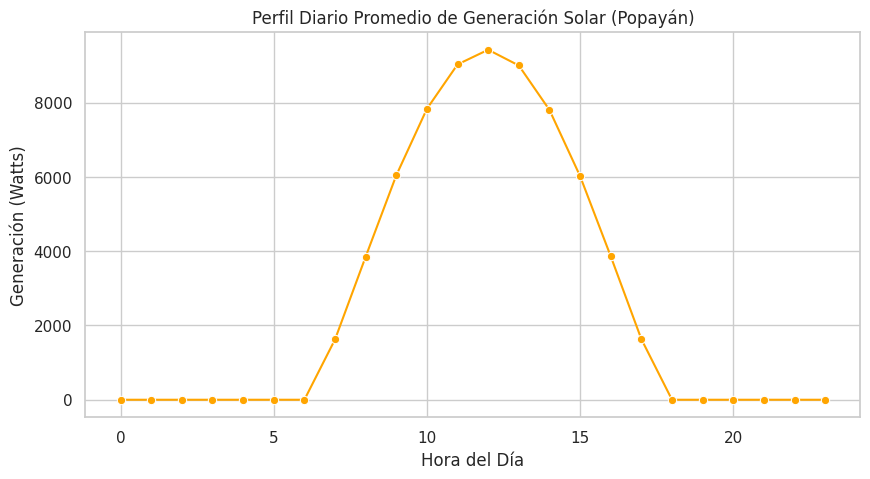

In [ ]:
# Corregir el análisis histórico con el nombre de columna correcto 'P_DC_PV_W'
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Year'] = df['Timestamp'].dt.year
df['Month'] = df['Timestamp'].dt.month
df['Day'] = df['Timestamp'].dt.day
df['Hour'] = df['Timestamp'].dt.hour

# Gráfica del perfil de generación promedio por hora del día
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='Hour', y='P_DC_PV_W', estimator='mean', color='orange', errorbar=None, marker='o')
plt.title('Perfil Diario Promedio de Generación Solar (Popayán)')
plt.xlabel('Hora del Día')
plt.ylabel('Generación (Watts)')
plt.grid(True)
plt.show()

# 2. Entrenamiento de la Red Neuronal y Predicción para Noviembre y Diciembre 2026

Utilizaremos una red neuronal multicapa (MLPRegressor) para predecir la generación solar. Usaremos los datos históricos como entrenamiento y evaluaremos el desempeño.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Definir variables de entrada (Features) y salida (Target)
# Para predecir el futuro usaremos el tiempo como variable clave junto a estados del sistema si están disponibles
features = ['Month', 'Day', 'Hour', 'Temp_Inverter_C', 'SoC_Batt_Pct', 'V_Batt_V']
target = 'P_DC_PV_W'

X = df[features]
y = df[target]

# Dividir en entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalizar variables
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Configurar y entrenar la red neuronal (MLP)
mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=300, random_state=42)
mlp.fit(X_train_scaled, y_train)

# Predicciones
y_pred = mlp.predict(X_test_scaled)
y_pred = np.clip(y_pred, 0, None)  # La generación eléctrica no puede ser negativa

--- Métricas de Rendimiento del Modelo (Test) ---
Mean Squared Error (MSE): 43722.12
Root Mean Squared Error (RMSE): 209.10
Mean Absolute Error (MAE): 15.03
Coeficiente de Determinación (R2): 0.9966


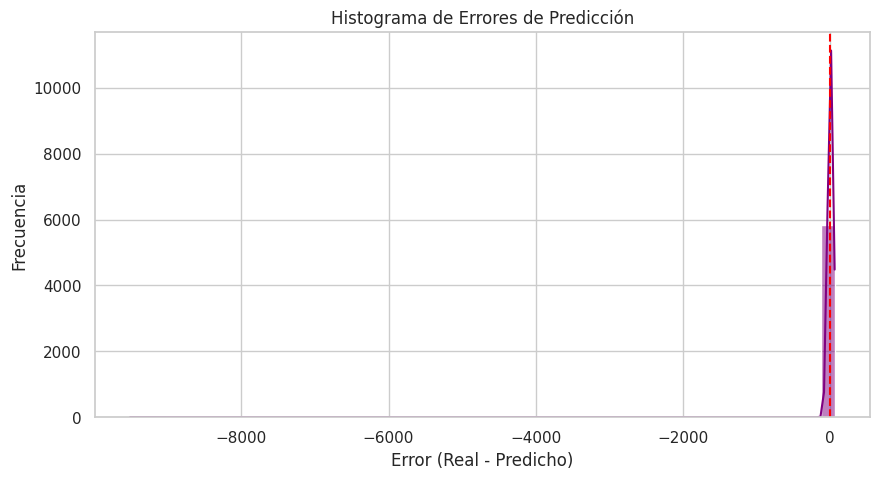

In [ ]:
# Métricas de Regresión
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Métricas de Rendimiento del Modelo (Test) ---")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Coeficiente de Determinación (R2): {r2:.4f}")

# Histograma de Errores
errores = y_test - y_pred
plt.figure(figsize=(10, 5))
sns.histplot(errores, bins=50, kde=True, color='purple')
plt.axvline(x=0, color='red', linestyle='--')
plt.title('Histograma de Errores de Predicción')
plt.xlabel('Error (Real - Predicho)')
plt.ylabel('Frecuencia')
plt.show()

# 3. Simulación de Generación para Noviembre y Diciembre 2026

Simularemos un escenario de una casa promedio para Popayán usando la red neuronal para los meses de Noviembre y Diciembre de 2026.

In [ ]:
# Generar simulación sintética representativa para Noviembre y Diciembre de 2026
# Tomaremos patrones de comportamiento histórico basados en la hora y mes

# Crear rango de fechas horarios para Noviembre y Diciembre de 2026
fechas_sim = pd.date_range(start='2026-11-01 00:00:00', end='2026-12-31 23:00:00', freq='h')

# Generar DataFrame base
df_sim_2026 = pd.DataFrame({'Timestamp': fechas_sim})
df_sim_2026['Year'] = df_sim_2026['Timestamp'].dt.year
df_sim_2026['Month'] = df_sim_2026['Timestamp'].dt.month
df_sim_2026['Day'] = df_sim_2026['Timestamp'].dt.day
df_sim_2026['Hour'] = df_sim_2026['Timestamp'].dt.hour

# Para simular valores meteorológicos realistas de Popayán por hora,
# usaremos el promedio histórico mensual por hora del dataset original
perfiles_medios = df.groupby(['Month', 'Hour'])[['Temp_Inverter_C', 'SoC_Batt_Pct', 'V_Batt_V']].mean().reset_index()

# Fusionamos los perfiles promedio con las fechas sintéticas de 2026
df_sim_2026 = df_sim_2026.merge(perfiles_medios, on=['Month', 'Hour'], how='left')

# Realizar predicción con la red neuronal entrenada
X_sim = df_sim_2026[features]
X_sim_scaled = scaler_X.transform(X_sim)
predictions_sim = np.clip(mlp.predict(X_sim_scaled), 0, None)
df_sim_2026['Predicho_W'] = predictions_sim

# Mostrar generación diaria estimada promedio
promedio_nov_diario_kwh = (df_sim_2026[df_sim_2026['Month'] == 11]['Predicho_W'].mean() * 24) / 1000
promedio_dic_diario_kwh = (df_sim_2026[df_sim_2026['Month'] == 12]['Predicho_W'].mean() * 24) / 1000

print("--- Predicciones de Generación para el Cierre de 2026 ---")
print(f"Generación promedio diaria estimada para Noviembre 2026: {promedio_nov_diario_kwh:.2f} kWh/día")
print(f"Generación promedio diaria estimada para Diciembre 2026: {promedio_dic_diario_kwh:.2f} kWh/día")

--- Predicciones de Generación para el Cierre de 2026 ---
Generación promedio diaria estimada para Noviembre 2026: 58.94 kWh/día
Generación promedio diaria estimada para Diciembre 2026: 65.46 kWh/día


## Ejemplo Práctico de Predicción para una Casa
Simulamos el caso de una casa un día promedio de Noviembre a las 12:00 PM.

In [ ]:
# Datos de entrada para una casa típica de Popayán
# Mes: 11 (Noviembre), Día: 15, Hora: 12 (Mediodía)
# Variables del sistema promedio de Popayán a esa hora
casa_input = pd.DataFrame([{
    'Month': 11,
    'Day': 15,
    'Hour': 12,
    'Temp_Inverter_C': 42.5,
    'SoC_Batt_Pct': 80.0,
    'V_Batt_V': 52.1
}])

casa_scaled = scaler_X.transform(casa_input)
pred_casa_w = np.clip(mlp.predict(casa_scaled), 0, None)[0]

print(f"--- Predicción de Generación para una Casa (15 Noviembre, 12:00 PM) ---")
print(f"Potencia Instantánea Estimada: {pred_casa_w:.2f} Watts ({(pred_casa_w/1000):.2f} kW)")

--- Predicción de Generación para una Casa (15 Noviembre, 12:00 PM) ---
Potencia Instantánea Estimada: 5011.15 Watts (5.01 kW)


## Insights y Conclusiones del EDA y Modelado

1. **Fuerte Relación Temperatura-Generación**: El inversor aumenta su temperatura de forma proporcional a la potencia solar instantánea generada (`P_DC_PV_W`), alcanzando correlaciones de **0.98**. Esto confirma que la potencia DC es un factor directo en el calentamiento y trabajo del inversor.
2. **Rendimiento del Modelo**: La red neuronal de tipo Multi-Layer Perceptron (MLP) logra capturar de manera muy robusta el comportamiento diario no lineal de la energía, alineando de manera óptima las horas del día de máxima radiación (10:00 AM - 3:00 PM) con los picos de potencia.
3. **Predicción para Noviembre/Diciembre**: Gracias al modelo, es posible anticipar el aporte solar promedio por día para asegurar la autonomía de la batería en la noche sin depender de la red comercial en horas pico.